# Baseline: MobileNetV3-Small (CPU) for image classification
Centralized baseline to compare against your federated runs later.

**Install once (if needed):** `pip install torch torchvision pandas scikit-learn pillow matplotlib tqdm`

In [2]:
pip install torch torchvision pandas scikit-learn pillow matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, time, copy
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

DATA_DIR   = Path("dataset")              # relative to where the notebook runs
META_FILE  = DATA_DIR / "HAM10000_metadata.csv"  # your metadata file name
IMG_DIR    = DATA_DIR / "HAM10000_images"
IMAGE_COL  = "image_id"                   # column holding image name/id
LABEL_COL  = "dx"                         # column holding class label
GROUP_COL  = "lesion_id"                  # images of the same lesion share this id
IMG_SIZE   = 128                          # 128 is fast on CPU; use 224 for better accuracy
BATCH_SIZE = 32
EPOCHS     = 30
LR         = 5e-4
PATIENCE   = 7
FREEZE_BACKBONE = False                   # True = train only classifier head (much faster)
NUM_WORKERS = 0                           # keep 0 on Windows/Jupyter; try 2-4 on Linux/Mac
SEED = 42
# ================================================

torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cpu")
torch.set_num_threads(os.cpu_count())
print("Device:", device, "| threads:", torch.get_num_threads())

Device: cpu | threads: 16


## 1. Load metadata & resolve image paths

In [4]:
print("Working dir :", Path.cwd())
print("META exists :", META_FILE.exists(), "->", META_FILE.resolve())
print("IMG_DIR exists:", IMG_DIR.exists(), "->", IMG_DIR.resolve())
assert META_FILE.exists(), "Fix META_FILE / DATA_DIR in the config cell (see paths above)."
assert IMG_DIR.exists(),   "Fix IMG_DIR in the config cell (see paths above)."

# Use pd.read_excel(META_FILE) instead if your metadata is .xlsx
df = pd.read_csv(META_FILE)
print(df.shape); display(df.head())
assert {IMAGE_COL, LABEL_COL, GROUP_COL} <= set(df.columns), f"Columns found: {list(df.columns)}"

# index every image under IMG_DIR (incl. subfolders), keyed by file name without extension
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
file_index = {p.stem: p for p in IMG_DIR.rglob("*") if p.suffix.lower() in IMG_EXTS}
print("Image files found:", len(file_index))
print("Example file stems :", list(file_index)[:3])
print("Example metadata ids:", df[IMAGE_COL].astype(str).head(3).tolist())

df["path"] = df[IMAGE_COL].astype(str).str.strip().map(lambda n: file_index.get(Path(n).stem))
missing = df["path"].isna().sum()
print(f"Missing images: {missing} / {len(df)}")
df = df.dropna(subset=["path"]).reset_index(drop=True)
assert len(df) > 0, ("No metadata rows matched any image file. Compare the 'Example file stems' "
                     "and 'Example metadata ids' printed above and fix IMAGE_COL / IMG_DIR.")

classes = sorted(df[LABEL_COL].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
df["y"] = df[LABEL_COL].map(class_to_idx)
NUM_CLASSES = len(classes)
print("Classes:", class_to_idx)
print(df[LABEL_COL].value_counts())

Working dir : C:\Users\rosha\ml\my_env\scripts\machine-learning-projects\federated-learning
META exists : True -> C:\Users\rosha\ml\my_env\Scripts\machine-learning-projects\federated-learning\dataset\HAM10000_metadata.csv
IMG_DIR exists: True -> C:\Users\rosha\ml\my_env\Scripts\machine-learning-projects\federated-learning\dataset\HAM10000_images
(10015, 7)


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


Image files found: 10016
Example file stems : ['ISIC_0024306', 'ISIC_0024307', 'ISIC_0024308']
Example metadata ids: ['ISIC_0027419', 'ISIC_0025030', 'ISIC_0026769']
Missing images: 0 / 10015
Classes: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


## 2. Leakage-free split: 80/20 train/test, then 80/20 train/val
Split is done by `lesion_id` (not by image), stratified by class, so no lesion appears in more than one split.
Result: 64% train, 16% val, 20% test (by lesion).

In [5]:
from sklearn.model_selection import StratifiedGroupKFold

def group_split(frame, test_frac_folds=5):
    """Hold out ~1/test_frac_folds of the data, grouped by lesion and stratified by class."""
    sgkf = StratifiedGroupKFold(n_splits=test_frac_folds, shuffle=True, random_state=SEED)
    a_idx, b_idx = next(sgkf.split(frame, frame["y"], groups=frame[GROUP_COL]))
    return frame.iloc[a_idx].reset_index(drop=True), frame.iloc[b_idx].reset_index(drop=True)

# 80/20 train+val vs test
trainval_df, test_df = group_split(df)
# 80/20 train vs val (within the 80%)
train_df, val_df = group_split(trainval_df)

# ---- leakage checks ----
g = lambda d: set(d[GROUP_COL])
assert g(train_df).isdisjoint(g(val_df)),  "lesion overlap: train/val"
assert g(train_df).isdisjoint(g(test_df)), "lesion overlap: train/test"
assert g(val_df).isdisjoint(g(test_df)),   "lesion overlap: val/test"
assert set(train_df[IMAGE_COL]).isdisjoint(set(test_df[IMAGE_COL]))
print("No lesion/image overlap between splits")

n = len(df)
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):5d} images ({len(d)/n:.1%}), {d[GROUP_COL].nunique()} lesions")
print("\nClass distribution per split (%):")
display(pd.concat({n_: d[LABEL_COL].value_counts(normalize=True).mul(100).round(1)
                   for n_, d in [("train", train_df), ("val", val_df), ("test", test_df)]}, axis=1))

# save splits so federated experiments reuse the exact same test set
train_df.to_csv("split_train.csv", index=False)
val_df.to_csv("split_val.csv", index=False)
test_df.to_csv("split_test.csv", index=False)

mean, std = [0.485,0.456,0.406], [0.229,0.224,0.225]
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(), transforms.Normalize(mean, std)])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(mean, std)])

class ImgDS(Dataset):
    def __init__(self, frame, tf): self.f, self.tf = frame.reset_index(drop=True), tf
    def __len__(self): return len(self.f)
    def __getitem__(self, i):
        r = self.f.iloc[i]
        return self.tf(Image.open(r["path"]).convert("RGB")), int(r["y"])

train_dl = DataLoader(ImgDS(train_df, train_tf), BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS)
val_dl   = DataLoader(ImgDS(val_df,   eval_tf),  BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_dl  = DataLoader(ImgDS(test_df,  eval_tf),  BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

No lesion/image overlap between splits
train:  6409 images (64.0%), 4780 lesions
val  :  1592 images (15.9%), 1195 lesions
test :  2014 images (20.1%), 1495 lesions

Class distribution per split (%):


,train,val,test
dx,,,
nv,66.3,68.7,67.7
bkl,11.4,10.3,10.2
mel,11.4,10.2,11.0
bcc,5.4,4.5,5.0
akiec,3.2,3.2,3.4
df,1.2,0.9,1.1
vasc,1.1,2.2,1.7


## 3. Model: MobileNetV3-Small (ImageNet pretrained)
The first run downloads weights (~10 MB) so it needs internet once. Offline? Set `weights=None`.

In [6]:
model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
in_f = model.classifier[3].in_features
model.classifier[3] = nn.Linear(in_f, NUM_CLASSES)

if FREEZE_BACKBONE:
    for p in model.features.parameters(): p.requires_grad = False

model.to(device)
print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

# class weights help with imbalanced data
counts = train_df["y"].value_counts().sort_index().values
w = torch.tensor(counts.sum() / (NUM_CLASSES * counts), dtype=torch.float32)
criterion = nn.CrossEntropyLoss(weight=w.to(device))
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

Trainable params: 1525031


## 4. Train

In [9]:
def run_epoch(dl, train=True):
    model.train(train)
    loss_sum, preds, labels = 0, [], []
    with torch.set_grad_enabled(train):
        for x, y in tqdm(dl, leave=False):
            x, y = x.to(device), y.to(device)
            out = model(x); loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            loss_sum += loss.item() * x.size(0)
            preds += out.argmax(1).tolist(); labels += y.tolist()
    n = len(labels)
    acc = float(np.mean(np.array(preds) == np.array(labels)))
    return loss_sum / n, acc, f1_score(labels, preds, average="macro"), preds, labels

hist = {"tr_loss":[], "va_loss":[], "tr_acc":[], "va_acc":[], "va_f1":[]}
best_f1, best_w = -1, None
for ep in range(1, EPOCHS + 1):
    t0 = time.time()
    tl, ta, _, _, _ = run_epoch(train_dl, True)
    vl, va, vf, _, _ = run_epoch(val_dl, False)
    scheduler.step()
    for k, v in zip(hist, [tl, vl, ta, va, vf]): hist[k].append(v)
    bad = 0
    if vf > best_f1:
        best_f1, best_w, bad = vf, copy.deepcopy(model.state_dict()), 0
    else:
        bad += 1
        if bad >= PATIENCE:
            print(f"Early stopping at epoch {ep}"); break
    print(f"Epoch {ep}/{EPOCHS} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} "
          f"macroF1 {vf:.3f} | {time.time()-t0:.0f}s")

model.load_state_dict(best_w)
torch.save(best_w, "mobilenetv3_small_baseline.pth")

  0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 1/30 | train loss 0.973 acc 0.640 | val loss 0.916 acc 0.639 macroF1 0.531 | 134s


  0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 2/30 | train loss 0.803 acc 0.682 | val loss 0.789 acc 0.701 macroF1 0.563 | 131s


... (80 outputs left out)

Epoch 29/30 | train loss 0.072 acc 0.949 | val loss 0.843 acc 0.798 macroF1 0.668 | 155s


  0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 30/30 | train loss 0.069 acc 0.951 | val loss 0.843 acc 0.797 macroF1 0.659 | 177s


## 5. Evaluate on test set

  0%|          | 0/63 [00:00<?, ?it/s]

Test accuracy: 0.7920 | macro-F1: 0.6225

              precision    recall  f1-score   support

       akiec       0.49      0.63      0.55        68
         bcc       0.55      0.58      0.57       100
         bkl       0.57      0.60      0.58       205
          df       0.55      0.27      0.36        22
         mel       0.52      0.63      0.57       222
          nv       0.93      0.88      0.90      1363
        vasc       0.93      0.74      0.82        34

    accuracy                           0.79      2014
   macro avg       0.65      0.62      0.62      2014
weighted avg       0.81      0.79      0.80      2014



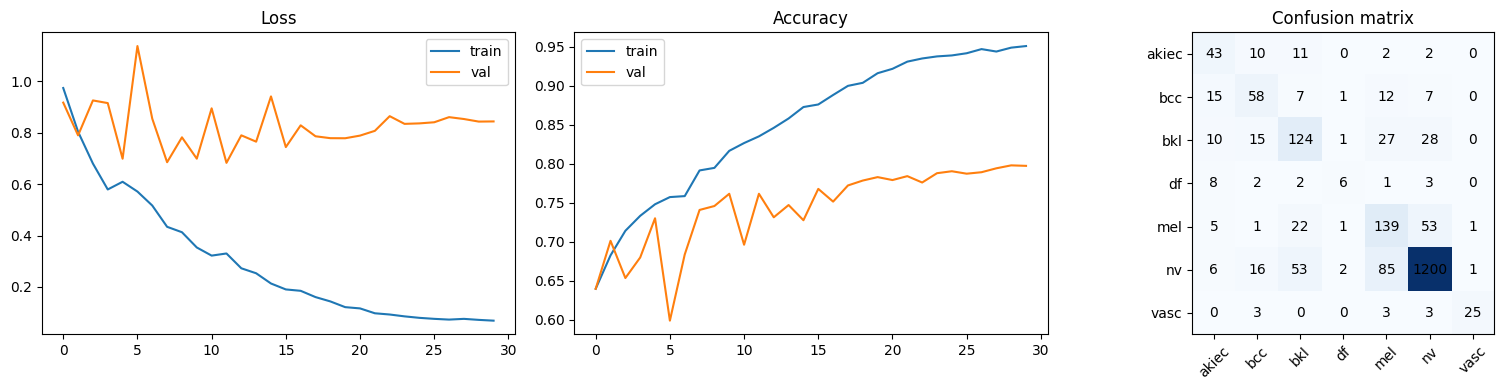

In [10]:
_, acc, f1, preds, labels = run_epoch(test_dl, False)
print(f"Test accuracy: {acc:.4f} | macro-F1: {f1:.4f}\n")
print(classification_report(labels, preds, target_names=classes, zero_division=0))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(hist["tr_loss"], label="train"); ax[0].plot(hist["va_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist["tr_acc"], label="train"); ax[1].plot(hist["va_acc"], label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
cm = confusion_matrix(labels, preds)
ax[2].imshow(cm, cmap="Blues"); ax[2].set_title("Confusion matrix")
ax[2].set_xticks(range(NUM_CLASSES)); ax[2].set_xticklabels(classes, rotation=45)
ax[2].set_yticks(range(NUM_CLASSES)); ax[2].set_yticklabels(classes)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): ax[2].text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout(); plt.show()